<a href="https://colab.research.google.com/github/duangkamon214/NBA-Player-Data/blob/main/NBA_player_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NBA Player Statistics Analysis
## 1. Introduction

*   This project analyzes NBA player statistics from the 2023-2024 season.
*   I chose this dataset because I am interested in basketball and wanted to practice data analysis with a topic that I enjoy.
*   The analysis focuses on scoring (PTS), player positions, age, minutes played (MP), assists (AST) and turnovers (TOV).
*   The goal is to practice using Python.








In [ ]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import numpy as np
# Load dataset
df = pd.read_csv("./nba-player-data.csv")


In [ ]:
# Plot settings
sns.set(style = "whitegrid")
plt.rcParams["figure.figsize"] = (10,5)

## 2. Data Exploration

Before analyzing the data, I first explored the dataset to understand
its structure, data types, and basic statistics.

In [ ]:
df.head()

,Rk,Player,Pos,Age,Tm,G,GS,MP,FG,FGA,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,1,Precious Achiuwa,PF-C,24,TOT,74,18,21.9,3.2,6.3,...,.616,2.6,4.0,6.6,1.3,0.6,0.9,1.1,1.9,7.6
1,1,Precious Achiuwa,C,24,TOR,25,0,17.5,3.1,6.8,...,.571,2.0,3.4,5.4,1.8,0.6,0.5,1.2,1.6,7.7
2,1,Precious Achiuwa,PF,24,NYK,49,18,24.2,3.2,6.1,...,.643,2.9,4.3,7.2,1.1,0.6,1.1,1.1,2.1,7.6
3,2,Bam Adebayo,C,26,MIA,71,71,34.0,7.5,14.3,...,.755,2.2,8.1,10.4,3.9,1.1,0.9,2.3,2.2,19.3
4,3,Ochai Agbaji,SG,23,TOT,78,28,21.0,2.3,5.6,...,.661,0.9,1.8,2.8,1.1,0.6,0.6,0.8,1.5,5.8


In [ ]:
df.tail()

,Rk,Player,Pos,Age,Tm,G,GS,MP,FG,FGA,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
731,568,Thaddeus Young,PF,35,PHO,10,0,8.9,1.1,2.1,...,.333,1.7,1.1,2.8,0.7,0.5,0.2,0.4,1.1,2.3
732,569,Trae Young,PG,25,ATL,54,54,36.0,8.0,18.7,...,.855,0.4,2.3,2.8,10.8,1.3,0.2,4.4,2.0,25.7
733,570,Omer Yurtseven,C,25,UTA,48,12,11.4,2.1,3.8,...,.679,1.5,2.8,4.3,0.6,0.2,0.4,0.8,1.1,4.6
734,571,Cody Zeller,C,31,NOP,43,0,7.4,0.6,1.4,...,.605,1.1,1.5,2.6,0.9,0.2,0.1,0.4,1.0,1.8
735,572,Ivica Zubac,C,26,LAC,68,68,26.4,5.0,7.6,...,.723,2.9,6.3,9.2,1.4,0.3,1.2,1.2,2.6,11.7


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 736 entries, 0 to 735
Data columns (total 30 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Rk      736 non-null    object
 1   Player  736 non-null    object
 2   Pos     736 non-null    object
 3   Age     736 non-null    object
 4   Tm      736 non-null    object
 5   G       736 non-null    object
 6   GS      736 non-null    object
 7   MP      736 non-null    object
 8   FG      736 non-null    object
 9   FGA     736 non-null    object
 10  FG%     728 non-null    object
 11  3P      736 non-null    object
 12  3PA     736 non-null    object
 13  3P%     690 non-null    object
 14  2P      736 non-null    object
 15  2PA     736 non-null    object
 16  2P%     723 non-null    object
 17  eFG%    728 non-null    object
 18  FT      736 non-null    object
 19  FTA     736 non-null    object
 20  FT%     677 non-null    object
 21  ORB     736 non-null    object
 22  DRB     736 non-null    ob

In [ ]:
df["Age"].head(10)

,Age
0,24
1,24
2,24
3,26
4,23
5,23
6,23
7,23
8,25
9,28


In [ ]:
df["Age"].unique()

array(['24', '26', '23', '25', '28', '30', '29', '31', '21', 'Age', '19',
       '22', '20', '35', '27', '34', '32', '36', '33', '38', '37', '39'],
      dtype=object)

In [ ]:
df["PTS"].unique()[:40]

array(['7.6', '7.7', '19.3', '5.8', '5.4', '6.7', '10.7', '8.0', '13.5',
       '16.5', '2.6', '7.1', '6.4', '30.4', '0.9', '11.6', '14.7', '15.1',
       '14.1', '0.0', '16.7', '2.2', '1.5', '11.7', '10.2', '13.3', 'PTS',
       '2.3', '4.4', '23.9', '22.6', '23.7', '10.3', '12.2', '19.9',
       '20.2', '18.2', '21.8', '3.3', '2.7'], dtype=object)

A duplicate header row was found in the dataset, which caused some columns to be read as object type.






In [ ]:
# Check which row contains a duplicate header.
df[df["Age"] == "Age"]

,Rk,Player,Pos,Age,Tm,G,GS,MP,FG,FGA,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
28,Rk,Player,Pos,Age,Tm,G,GS,MP,FG,FGA,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS


The duplicate header was found in row 28.

## 3. Data Cleaning

The dataset contains a duplicate header row, which can affect the data types.
I removed this row before continuing the analysis.

In [ ]:
# Create a new DataFrame.
# Remove the duplicate header row.
df = df[df["Player"] != "Player"].copy()

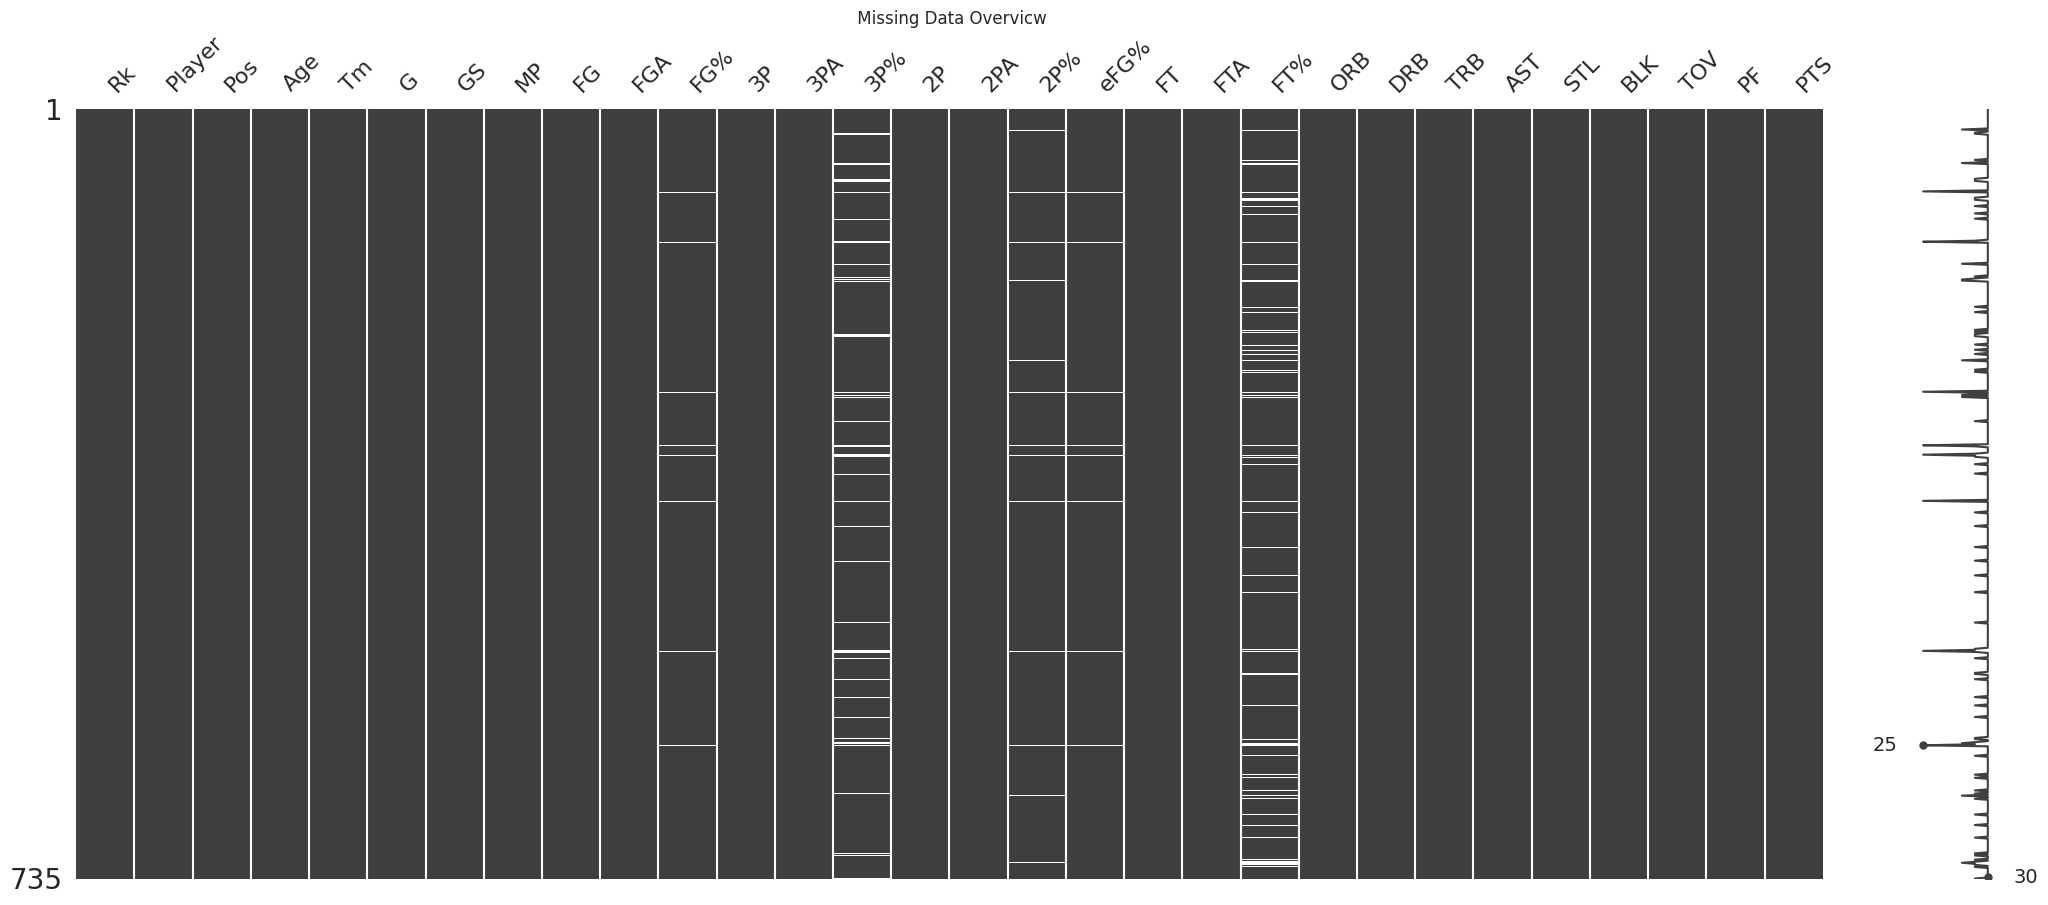

In [ ]:
# Check which rows contain missing values.
msno.matrix(df)
plt.title(" Missing Data Overvicw")
plt.show()


The missing data overview shows that missing values are mainly found in FG%, 3P%, 2P%, eFG%, and FT%

## 4. Data Analysis

4.1 Top 10 player by PTS

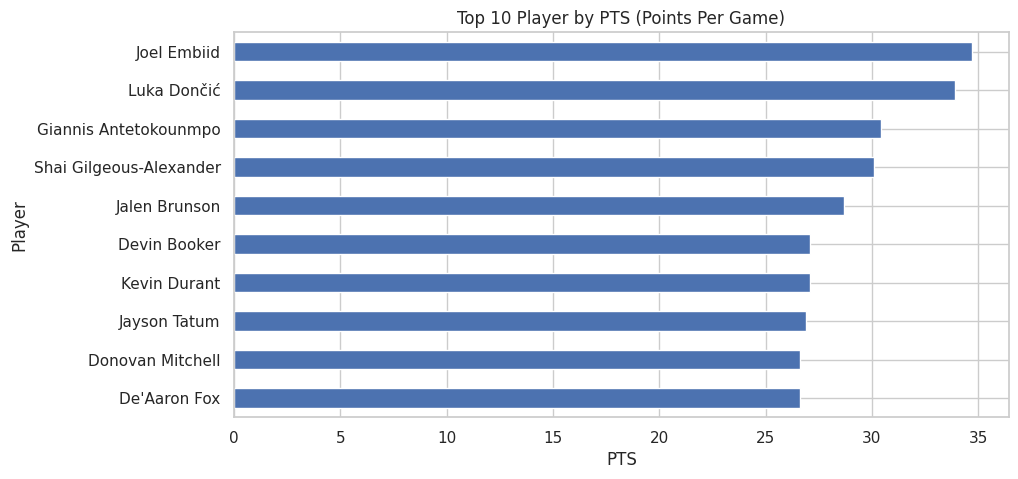

In [ ]:
# Exploratory data analysis (EDA)
# Top 10 player by PTS
df["PTS"] = pd.to_numeric(df["PTS"], errors = "coerce")
top_10 = df.sort_values("PTS", ascending = False)
top_10.head(10)[["Player","PTS"]].sort_values("PTS").plot(kind = "barh" , x = "Player",y = "PTS", title = "Top 10 Player by PTS (Points Per Game)" , legend = False)
plt.xlabel('PTS')
plt.ylabel("Player")
plt.show()

4.2 Avarage PTS by position

In [ ]:
# Avarage PTS by position
df.groupby("Pos")["PTS"].mean()


,PTS
Pos,
C,7.729412
C-PF,7.100000
PF,8.265306
PF-C,7.600000
PF-SF,5.700000
PG,8.640816
PG-SG,12.925000
SF,7.225161
SF-PF,9.800000


In [ ]:
df.groupby("Pos").size()

,0
Pos,
C,119
C-PF,3
PF,147
PF-C,1
PF-SF,1
PG,147
PG-SG,4
SF,155
SF-PF,2


In [ ]:
main_pos = ["C","PF","PG","SF","SG"]
df_main = df[df["Pos"].isin(main_pos)]
avg_pos = df_main.groupby("Pos")["PTS"].mean()
avg_pos

,PTS
Pos,
C,7.729412
PF,8.265306
PG,8.640816
SF,7.225161
SG,8.118182


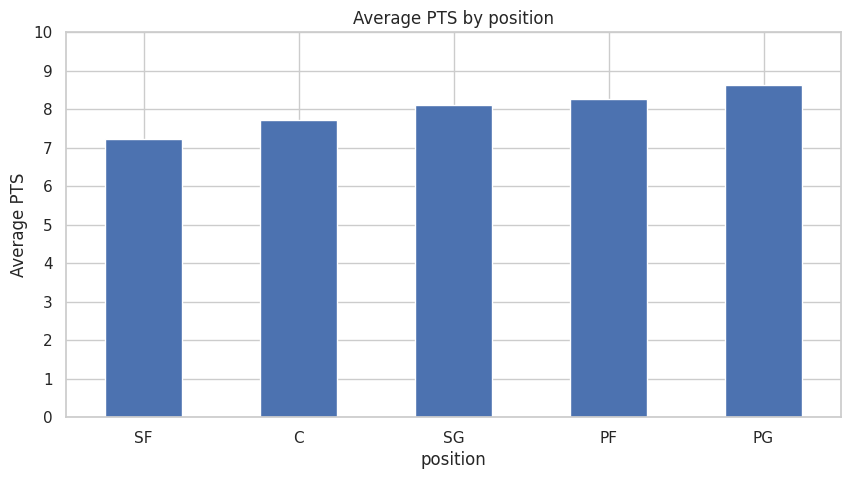

In [ ]:
avg_pos = df_main.groupby("Pos")["PTS"].mean()
avg_pos = avg_pos.reindex(["SF","C","SG","PF","PG"])
avg_pos.plot(kind = "bar", title = "Average PTS by position")
plt.xlabel("position")
plt.xticks(rotation = 0)
plt.yticks(range(0,11,1))
plt.ylabel("Average PTS")
plt.show()

4.3 Average PTS by age group

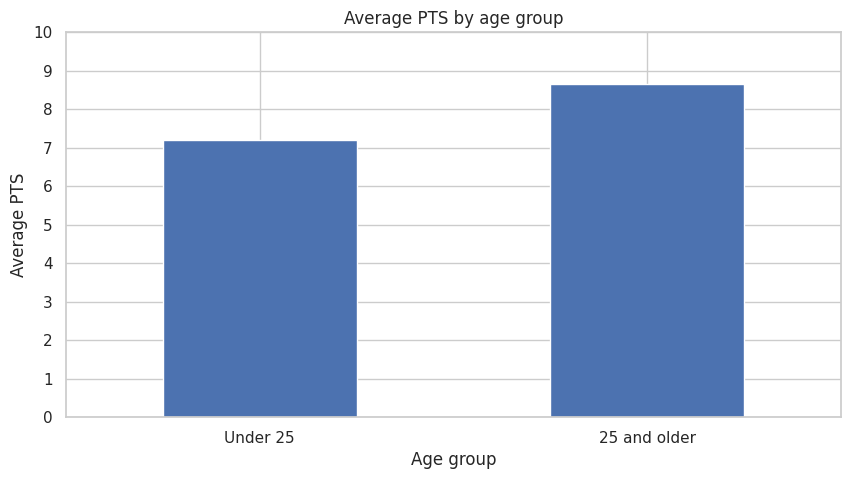

In [ ]:
# Average PTS by age group
df["Age"]=pd.to_numeric(df["Age"],errors = "coerce")
df["Age_group"]= np.where(df["Age"] < 25, "Under 25", "25 and older")
avg_age = df.groupby("Age_group")["PTS"].mean()
avg_age = avg_age.reindex(["Under 25","25 and older"])
avg_age.plot(kind = "bar", title = "Average PTS by age group")
plt.xlabel("Age group")
plt.xticks(rotation = 0)
plt.ylabel("Average PTS")
plt.yticks(range(0,11,1))
plt.show()


In [ ]:
avg_age

,PTS
Age_group,
Under 25,7.193968
25 and older,8.643571


4.4 Average PTS by playing time

In [ ]:
# Average PTS by playing time
df["MP"] = pd.to_numeric(df["MP"], errors = "coerce")

In [ ]:
pd.cut(df["MP"], bins = [0,13,24,38]).value_counts().sort_values()

,count
MP,
"(24, 38]",233
"(13, 24]",244
"(0, 13]",258


In [ ]:
df["mp_group"] = pd.cut(df["MP"],bins = [0,13,24,38])
df[["MP","mp_group"]].head()

,MP,mp_group
0,21.9,"(13, 24]"
1,17.5,"(13, 24]"
2,24.2,"(24, 38]"
3,34.0,"(24, 38]"
4,21.0,"(13, 24]"


In [ ]:
ave_mpgroup = df.groupby("mp_group" , observed=True)["PTS"].mean()
ave_mpgroup

,PTS
mp_group,
"(0, 13]",2.625194
"(13, 24]",6.601639
"(24, 38]",15.486266


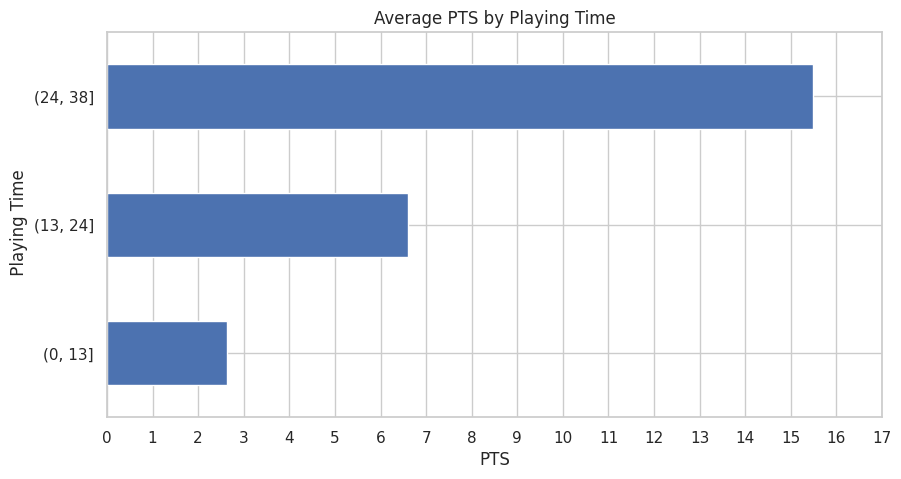

In [ ]:
ave_mpgroup.plot(kind = "barh" , title = "Average PTS by Playing Time")
plt.xlabel("PTS")
plt.xticks(range(0,18,1))
plt.ylabel(" Playing Time")
plt.show()

4.5 Assist vs Turnover

In [ ]:
# Assist vs Turnover
df["AST"].corr(df["TOV"])

np.float64(0.8313129477608738)

The correlation coefficient between AST and TOV is 0.83, indicating a strong positive relationship.

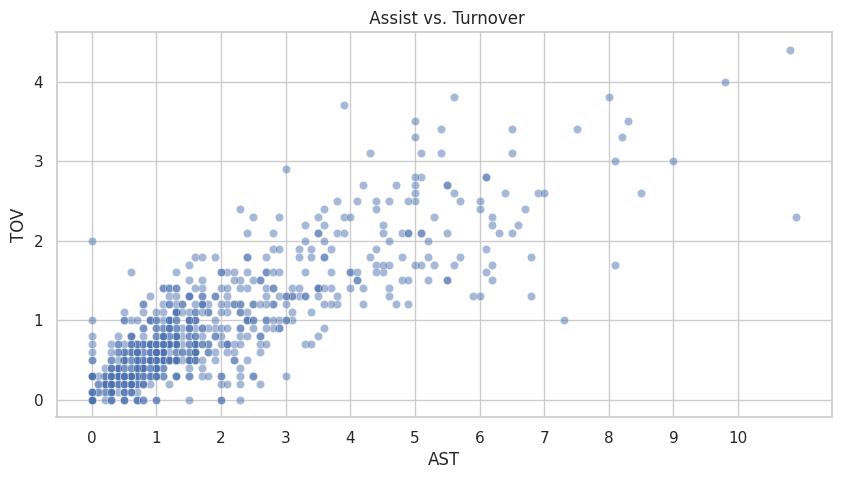

In [ ]:
df["AST"]=pd.to_numeric(df["AST"],errors = "coerce")
df["TOV"]=pd.to_numeric(df["TOV"],errors = "coerce")
sns.scatterplot(data = df , x = "AST" , y = "TOV" , alpha = 0.5)
plt.title(" Assist vs. Turnover")
plt.xlabel("AST")
plt.ylabel("TOV")
plt.xticks(range(0,11,1))
plt.yticks(range(0,5,1))
plt.show()

# 5. Insights gained from the analysis.
*   Based on this dataset, players in the PG position have the highest average PTS, at 8.64 points.
*   Players aged 25 and older have a higher average PTS than players under 25, with 8.64 and 7.19 points per game, respectively.
*   The analysis shows a strong positive relationship between assists and turnovers, with a correlation coefficient of 0.83. This suggests that players with higher assist numbers tend to have higher turnover numbers.

